# KDnuggets 기사로 본 AI·데이터 기술 트렌드 (2026년 6월~10월)

이 노트북은 KDnuggets 기사 200건의 메타데이터로 최근 AI·데이터 기술 트렌드를 분석한 리포트입니다. 분석 코드, 결과, 해석을 함께 담았습니다.

**실행 방법:** `kdnuggets_articles_20261029.csv` 파일을 이 노트북과 같은 폴더에 두고 위에서부터 순서대로 실행하세요. 필요한 패키지는 `pandas`, `matplotlib`입니다.

## 0. 환경 설정

차트의 한글이 깨지지 않도록, 운영체제별로 설치된 한글 폰트를 찾아 적용합니다. macOS는 AppleGothic, Windows는 맑은 고딕, Colab·Linux는 나눔고딕이나 Noto Sans CJK를 사용합니다.

In [1]:
import re

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import font_manager

CSV_PATH = "kdnuggets_articles_20261029.csv"  # 노트북과 같은 폴더


def set_korean_font():
    """설치된 한글 폰트 중 첫 번째를 matplotlib 기본 폰트로 지정"""
    candidates = ["AppleGothic", "Malgun Gothic", "NanumGothic",
                  "Noto Sans CJK KR", "Noto Sans CJK JP"]
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in candidates:
        if name in installed:
            plt.rcParams["font.family"] = name
            print(f"한글 폰트: {name}")
            break
    else:
        print("한글 폰트를 찾지 못했어요. Colab이라면 "
              "!apt-get -qq install fonts-nanum 실행 후 런타임을 재시작하세요.")
    plt.rcParams["axes.unicode_minus"] = False


set_korean_font()
pd.set_option("display.max_colwidth", 100)
plt.rcParams["figure.dpi"] = 110

한글 폰트: Noto Sans CJK JP


## 1. 분석 개요

이 리포트는 KDnuggets에 게시된 기사 200건의 메타데이터로 최근 AI·데이터 기술 트렌드를 정리한 것입니다. 데이터는 2026년 10월 29일에 KDnuggets의 WordPress REST API(`/wp-json/wp/v2/posts`)로 수집했고, 수집 항목은 제목, URL, 요약문, 저자, 발행일(UTC), 카테고리, 수집일입니다. 대상 기간은 2026년 6월 25일부터 10월 28일까지 약 4개월이며, 결측값은 없습니다.

| 항목 | 내용 |
|---|---|
| 기사 수 | 200건 |
| 기간 | 2026-06-25 ~ 2026-10-28 |
| 월별 기사 수 | 6월 7건, 7월 48건, 8월 46건, 9월 50건, 10월 49건 |
| 수집일 | 2026-10-29 |
| 결과 파일 | `kdnuggets_articles_20261029.csv` |

In [2]:
df = pd.read_csv(CSV_PATH, parse_dates=["published", "collected_at"])

print(f"기사 수: {len(df)}건")
print(f"기간: {df['published'].min():%Y-%m-%d} ~ {df['published'].max():%Y-%m-%d}")
print(f"수집일: {df['collected_at'].min():%Y-%m-%d}")
print("\n[결측값]")
print(df.isna().sum().to_string())
df.head(3)

기사 수: 200건
기간: 2026-06-25 ~ 2026-10-28
수집일: 2026-10-29

[결측값]
title           0
url             0
summary         0
author          0
published       0
category        0
collected_at    0


,title,url,summary,author,published,category,collected_at
0,Access Multiple AI Models in Your Python Apps Using OpenRouter,https://www.kdnuggets.com/access-multiple-ai-models-in-your-python-apps-using-openrouter,"Learn how to get started with the OpenRouter API to call multiple AI models through one API, com...",Bala Priya C,2026-10-28 14:00:00,Originals,2026-10-29 11:06:55
1,Can This Open-Source Model Beat AI Detectors? Let’s Test It Locally,https://www.kdnuggets.com/can-this-open-source-model-beat-ai-detectors-lets-test-it-locally,"Can a free, open-source AI humanizer beat paid tools? We tested a 12B model locally and compared...",Abid Ali Awan,2026-10-28 12:00:00,Originals,2026-10-29 11:06:55
2,Which Local LMs are Best For Which Tasks,https://www.kdnuggets.com/which-local-lms-are-best-for-which-tasks,"A local language model is one whose actual weights, the enormous file of learned numbers that co...",Shittu Olumide,2026-10-28 12:00:00,Originals,2026-10-29 11:06:55


In [3]:
monthly_counts = df["published"].dt.to_period("M").value_counts().sort_index()
monthly_counts.rename("기사 수").to_frame()

,기사 수
published,
2026-06,7
2026-07,48
2026-08,46
2026-09,50
2026-10,49


### 카테고리 컬럼을 쓰지 않은 이유

In [4]:
cat = df["category"].value_counts().rename("기사 수").to_frame()
cat["비중(%)"] = (cat["기사 수"] / len(df) * 100).round(1)
cat

,기사 수,비중(%)
category,,
Originals,186,93.0
Products and Services,7,3.5
"Cheat Sheets, Originals",5,2.5
News,2,1.0


수집된 `category` 컬럼은 주제 분석에 쓸 수 없었습니다. 200건 중 186건(93%)이 "Originals"였고, 나머지도 "Products and Services"(7건), "Cheat Sheets, Originals"(5건), "News"(2건)로 기술 주제와 무관한 분류였기 때문입니다. 그래서 **제목과 요약문을 합친 텍스트에 키워드 규칙(정규표현식)을 적용해 주제를 분류**했습니다. 한 기사가 여러 주제에 동시에 해당할 수 있으므로 주제별 비율의 합은 100%를 넘습니다. 월별 분석에서는 6월 기사가 7건뿐이어서 7월에 합쳐 집계했습니다.

## 2. 핵심 요약

기술 주제 중에서는 AI 에이전트가 압도적인 1위(30.5%)입니다. 그 뒤로 로컬·소형 모델과 추론·비용 최적화를 묶은 "싸고 가볍게" 흐름이 기사 네 건 중 한 건꼴로 나타납니다. AI 코딩 도구는 "써보기"에서 "검증하기"로 관심이 옮겨가고 있고, 모델 출시·리뷰 글은 매달 20% 이상 꾸준합니다. AI 시대에 맞춘 직무 재편을 다루는 글이 눈에 띄며, pandas·Polars 같은 데이터 도구의 기본기 글도 여전히 큰 비중을 차지합니다.

## 3. 주제별 비중

### 3.1 키워드 규칙으로 주제 분류

제목과 요약문을 소문자로 바꾼 뒤, 주제별 정규표현식 중 하나라도 일치하면 해당 주제로 분류합니다. 전체 규칙은 부록에 표로 정리했습니다.

In [5]:
THEMES = {
    "AI 에이전트": r"\bagent|agentic|autonomous|multi-agent",
    "AI 코딩·바이브 코딩": r"coding agent|coding assistant|claude code|vibe coding|ai-generated code"
                     r"|coding model|ai coding|codex|gemini cli|pi coding",
    "로컬·소형 모델": r"\blocal\b|locally|small language|\bslm|ollama|llama\.cpp|\bmlx\b|on-device|smol",
    "MCP": r"\bmcp\b|model context protocol",
    "RAG·검색": r"\brag\b|retrieval",
    "추론·비용 최적화": r"inference|latency|quantiz|token|kv cache|speculative|prun|cost|cheap",
    "프롬프트·명세 엔지니어링": r"prompt|specification engineering|constrain"
                        r"|structured (?:output|generation)|outlines",
    "파인튜닝·학습": r"fine-tun|training|pretrain",
    "모델 출시·리뷰": r"gemini|claude|chatgpt|openai|deepseek|qwen|grok|kimi|muse|gemma|minimax|mythos|review",
    "평가·신뢰성": r"\beval|benchmark|hallucinat|trust|check",
    "커리어·학습": r"roadmap|career|course|interview|resources|\brole|job|engineer in 2026|learn",
    "Python·데이터 도구": r"pandas|polars|\bpython\b|numba|\buv\b|marimo|csv|json|sql|docker",
    "고전 ML·통계": r"statistic|probability|time series|scikit-learn|algorithm"
                  r"|feature engineering|central limit",
    "거버넌스·사회": r"eu ai act|regulat|data center|job market|leadership|enterprise",
    "음성·멀티모달": r"voice|transcri|video|vision|image|speech|whisper",
}

df["text"] = (df["title"] + " " + df["summary"]).str.lower()
for theme, pattern in THEMES.items():
    df[theme] = df["text"].str.contains(pattern, regex=True)

# 6월은 7건뿐이라 7월에 합쳐 집계
df["month"] = df["published"].dt.to_period("M").astype(str).replace({"2026-06": "2026-07"})


def show_titles(theme, n=8):
    """특정 주제로 분류된 기사 제목 미리보기"""
    return df.loc[df[theme], ["published", "title"]].head(n).reset_index(drop=True)

### 3.2 주제별 기사 수와 비중

In [6]:
theme_summary = (
    df[list(THEMES)].sum()
    .sort_values(ascending=False)
    .rename("기사 수")
    .to_frame()
)
theme_summary["비중(%)"] = (theme_summary["기사 수"] / len(df) * 100).round(1)
theme_summary.insert(0, "순위", range(1, len(theme_summary) + 1))
theme_summary

,순위,기사 수,비중(%)
커리어·학습,1,68,34.0
AI 에이전트,2,61,30.5
모델 출시·리뷰,3,44,22.0
Python·데이터 도구,4,43,21.5
로컬·소형 모델,5,28,14.0
추론·비용 최적화,6,25,12.5
AI 코딩·바이브 코딩,7,19,9.5
평가·신뢰성,8,18,9.0
프롬프트·명세 엔지니어링,9,16,8.0
파인튜닝·학습,10,15,7.5


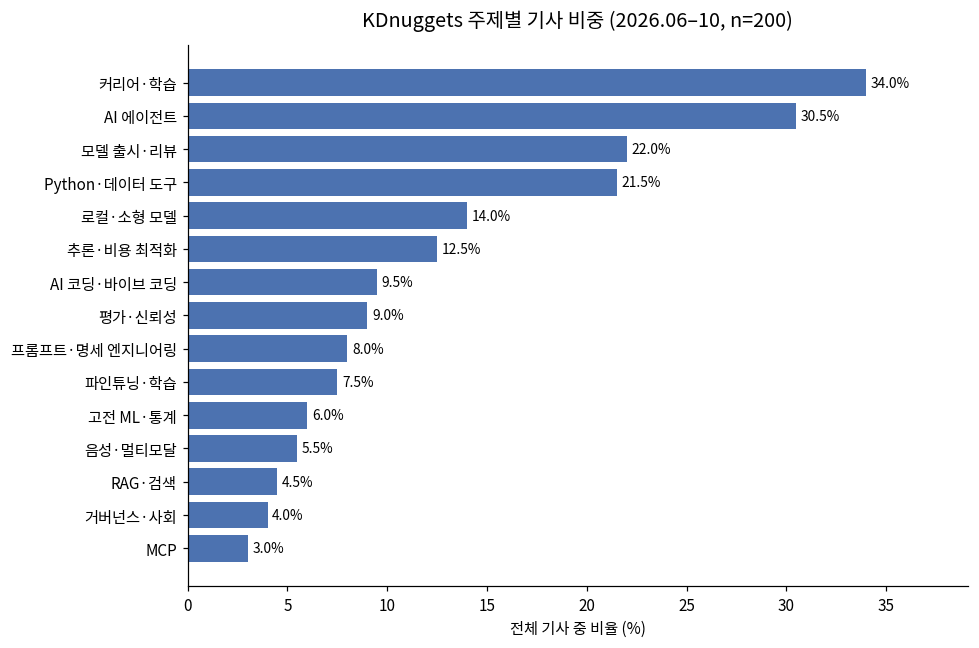

In [7]:
plot_data = theme_summary["비중(%)"].sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(plot_data.index, plot_data.values, color="#4C72B0")
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
ax.set_title(f"KDnuggets 주제별 기사 비중 (2026.06–10, n={len(df)})", fontsize=13, pad=12)
ax.set_xlabel("전체 기사 중 비율 (%)")
ax.set_xlim(0, plot_data.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

커리어·학습이 1위로 집계됐지만, 요약문에 흔히 쓰이는 "learn" 같은 단어가 키워드 규칙에 걸리면서 부풀려졌을 가능성이 큽니다. 실질적으로 가장 큰 기술 주제는 AI 에이전트로 보는 것이 타당합니다.

## 4. 주요 트렌드

### 4.1 AI 에이전트가 가장 큰 기술 주제

에이전트 관련 기사는 61건(30.5%)이고, 다루는 범위도 넓습니다. "Building Your First AI Agent in Python with the OpenAI Agents SDK", "Building AI Agents with Docker Agent", "10 Agentic AI Frameworks You Should Know in 2026" 같은 구축 입문 글부터 "How to Build Effective Evals for AI Agents", "Orchestration and Execution: How JONI Approaches the Agent Layer", "A Guide to Saving Token Usage with Multi-Agent AI", "5 Tools for Building and Deploying AI Agents in Production" 같은 평가·운영 단계 글까지 이어집니다.

In [8]:
show_titles("AI 에이전트", n=10)

,published,title
0,2026-10-26 14:00:00,Building Your First AI Agent in Python with the OpenAI Agents SDK
1,2026-10-23 12:00:00,5 Free AI Coding Agents You Should Try in 2026
2,2026-10-22 12:00:00,Google Open-Sources Harness²: Self-Improving AI Agents Without Retraining
3,2026-10-21 12:00:00,5 Best GitHub Repositories for AI Agent Skills
4,2026-10-19 16:00:00,"Claude Haiku 5.5: What’s New and How to Use It for Fast, Cheap AI Workflows"
5,2026-10-16 14:00:00,Agentic RAG vs. Naive RAG: When Your Retrieval System Should Think for Itself
6,2026-10-15 14:00:00,"Building AI Applications with OGX, the Open-Source Agentic API Server"
7,2026-10-13 14:00:00,The Roadmap to Mastering Agentic AI Systems in 2026
8,2026-10-08 14:00:00,Building AI Agents with Docker Agent
9,2026-10-08 12:00:00,7 Best Resources to Learn About Self-Evolving AI Agents


RAG는 독립 주제로는 4.5%에 그쳤고, 에이전트 관점에서 다시 해석되는 경향이 보입니다. "Agentic RAG vs. Naive RAG: When Your Retrieval System Should Think for Itself", "From RAG to Agentic AI", "Your RAG Pipeline Is Probably Useless. Here's a Better Alternative" 같은 제목이 그 예입니다. MCP 관련 글("Build Your First MCP Server in Python", "Top 5 MCP Servers for High-Performance Agentic Development", "MCP Explained in 5 Minutes")도 에이전트가 외부 도구와 연결되는 표준에 대한 관심이라는 점에서 같은 흐름에 속합니다.

In [9]:
pd.concat({"RAG·검색": show_titles("RAG·검색", n=9), "MCP": show_titles("MCP", n=6)})

published  \
RAG·검색 0 2026-10-16 14:00:00   
       1 2026-10-12 12:00:00   
       2 2026-09-29 12:00:36   
       3 2026-09-15 12:00:29   
       4 2026-09-08 16:00:12   
       5 2026-08-28 14:00:54   
       6 2026-08-07 12:00:30   
       7 2026-08-06 16:00:53   
       8 2026-06-29 14:00:50   
MCP    0 2026-10-09 14:00:00   
       1 2026-09-24 14:00:51   
       2 2026-07-25 13:00:37   
       3 2026-07-23 12:00:42   
       4 2026-07-20 12:00:25   
       5 2026-06-30 14:00:14   

                                                                                           title  
RAG·검색 0           Agentic RAG vs. Naive RAG: When Your Retrieval System Should Think for Itself  
       1                                            10 Hugging Face Models Worth Knowing in 2026  
       2                                                  5 Free Courses to Learn AI Engineering  
       3       5 Free Microsoft GitHub Courses to Learn Data Science and Artificial Intelligence  
       4  From RAG to Agentic AI: Building the Next Generation of Intelligent Enterprise Systems  
       5                                                  The Local AI Stack for Productive SLMs  
       6                                              5 Free Courses to Learn Modern AI and LLMs  
       7                        Beyond Bots: Rethinking AI Support with a Hybrid AI Architecture  
       8                      Your RAG Pipeline Is Probably Useless. Here’s a Better Alternative  
MCP    0                          Build Your First MCP Server in Python (Stateless Spec Edition)  
       1                                                              MCP Explained in 5 Minutes  
       2                                         KDnuggets Weekly Roundup: Week of July 20, 2026  
       3                                  7 Best Claude Code Alternatives for CLI Agentic Coding  
       4                              Top 5 MCP Servers for High-Performance Agentic Development  
       5                                               Building Local AI Systems: Qwen3.6 + MCPs

### 4.2 "싸고 가볍게": 로컬·소형 모델과 비용 최적화

로컬·소형 모델(14%)과 추론·비용 최적화(12.5%)를 합치면 전체 기사의 약 4분의 1입니다. 도구 측면에서는 Ollama, llama.cpp, Apple Silicon용 MLX, Hugging Face smolLM3·SmolVLM2가 자주 등장하고, 모델 측면에서는 Qwen, Gemma 같은 오픈 모델을 로컬에서 코딩 에이전트나 문서 파서로 쓰는 글이 많습니다.

기법을 다루는 글도 구체적입니다. SLM 최적화 시리즈(KV 캐시로 프롬프트 접두부 재사용, 길이 기준 배칭, 출력 공간 제한)를 비롯해 "Quantization and Pruning Methods to Make Your LLM Leaner", "Speed Up LLM Inference with DSpark Speculative Decoding", "12 Ways to Reduce LLM Latency and Inference Costs in Production", "5 Proven Techniques for Token Compression and Prompt Optimization" 등이 있습니다. "5 Free LLM API Providers You Can Use in 2026", "7 Open-Source AI Tools That Can Replace Paid Subscriptions", "5 AI Coding Subscription Plans That Give Developers the Best Value"처럼 비용 절감을 직접 다루는 글도 꾸준합니다.

In [10]:
pd.concat({
    "로컬·소형 모델": show_titles("로컬·소형 모델", n=10),
    "추론·비용 최적화": show_titles("추론·비용 최적화", n=10),
})

published  \
로컬·소형 모델  0 2026-10-28 12:00:00   
          1 2026-10-28 12:00:00   
          2 2026-10-20 12:00:00   
          3 2026-10-15 12:00:34   
          4 2026-09-30 12:00:18   
          5 2026-09-25 14:00:07   
          6 2026-09-22 12:00:28   
          7 2026-09-18 14:00:34   
          8 2026-08-31 14:00:00   
          9 2026-08-28 14:00:54   
추론·비용 최적화 0 2026-10-27 12:00:00   
          1 2026-10-19 16:00:00   
          2 2026-10-19 12:00:43   
          3 2026-10-15 12:00:34   
          4 2026-10-14 12:00:00   
          5 2026-10-06 14:00:20   
          6 2026-10-02 12:00:00   
          7 2026-09-14 12:00:09   
          8 2026-09-04 14:00:07   
          9 2026-09-04 12:00:38   

                                                                                     title  
로컬·소형 모델  0            Can This Open-Source Model Beat AI Detectors? Let’s Test It Locally  
          1                                       Which Local LMs are Best For Which Tasks  
          2                                                   5 Docker Containers for Devs  
          3                     7 Open-Source AI Tools That Can Replace Paid Subscriptions  
          4             Ollama for Managing Local Language Models: A KDnuggets Cheat Sheet  
          5        Batching by Length Instead of Looping Item by Item for SLM Optimization  
          6                      7 Open-Source Alternatives to ChatGPT You Can Run Locally  
          7          Reusing the Prompt Prefix with a Key-Value Cache for SLM Optimization  
          8                        Speed Up LLM Inference with DSpark Speculative Decoding  
          9                                         The Local AI Stack for Productive SLMs  
추론·비용 최적화 0  Google Gemini Omni: What It Actually Does, What It Costs, and How It Compares  
          1    Claude Haiku 5.5: What’s New and How to Use It for Fast, Cheap AI Workflows  
          2                              7 Checks to Run Before Trusting AI-Generated Code  
          3                     7 Open-Source AI Tools That Can Replace Paid Subscriptions  
          4                                   5 Fun Projects for LLM Inference Engineering  
          5                                                  Who Pays for AI Data Centers?  
          6              5 Proven Techniques for Token Compression and Prompt Optimization  
          7                 Why DeepSeek-V4.1-Flash Is Such an Exciting Open Model Release  
          8                               Switchyard: NVIDIA’s Open Source Routing Library  
          9                                   5 Free LLM API Providers You Can Use in 2026

### 4.3 AI 코딩: "써보기"에서 "검증하기"로

AI 코딩·바이브 코딩 관련 글은 19건(9.5%)입니다. "5 Free AI Coding Agents You Should Try in 2026", "7 Best Claude Code Alternatives for CLI Agentic Coding", "I Tested 5 AI Coding Assistants for a Month" 같은 도구 비교 글이 중심이지만, "7 Checks to Run Before Trusting AI-Generated Code", "10 Rules for Getting Better Results from AI Coding Agents", "Top 10 Open-Source Benchmarks for AI Coding Agents in 2026", "5 Things Vibe Coding Gets Right and 5 Things It Gets Wrong"처럼 결과물의 신뢰성과 한계를 다루는 글이 함께 나타납니다. 할루시네이션 평가("Language Model Hallucination Evaluation with GraphEval")를 포함한 평가·신뢰성 주제도 9%를 차지합니다.

프롬프트 영역에서는 "Specification Engineering: The New Skill After Prompt Engineering"이라는 제목처럼, 문장 하나하나를 다듬는 기술에서 요구사항과 제약을 명세하는 쪽으로 관점이 옮겨가는 흐름도 보입니다. 구조화된 출력("Structured Language Model Generation with Outlines", "An Introductory Guide to Practical Constraint Decoding")도 같은 맥락입니다.

In [11]:
pd.concat({
    "AI 코딩·바이브 코딩": show_titles("AI 코딩·바이브 코딩", n=10),
    "평가·신뢰성": show_titles("평가·신뢰성", n=8),
    "프롬프트·명세 엔지니어링": show_titles("프롬프트·명세 엔지니어링", n=8),
})

published  \
AI 코딩·바이브 코딩  0 2026-10-23 12:00:00   
              1 2026-10-21 12:00:00   
              2 2026-10-19 12:00:43   
              3 2026-10-15 12:00:34   
              4 2026-10-07 12:00:00   
              5 2026-09-24 14:00:51   
              6 2026-09-08 14:02:37   
              7 2026-08-26 12:00:50   
              8 2026-08-21 14:00:58   
              9 2026-08-20 12:00:38   
평가·신뢰성        0 2026-10-20 14:00:00   
              1 2026-10-19 12:00:43   
              2 2026-10-15 17:00:59   
              3 2026-10-07 16:00:00   
              4 2026-09-23 15:00:47   
              5 2026-09-16 12:00:50   
              6 2026-09-09 14:00:50   
              7 2026-09-02 14:00:11   
프롬프트·명세 엔지니어링 0 2026-10-22 12:00:00   
              1 2026-10-09 14:00:00   
              2 2026-10-02 12:00:00   
              3 2026-09-18 14:00:34   
              4 2026-09-18 12:00:22   
              5 2026-09-02 12:00:39   
              6 2026-08-27 14:00:24   
              7 2026-08-13 12:00:17   

                                                                                     title  
AI 코딩·바이브 코딩  0                             5 Free AI Coding Agents You Should Try in 2026  
              1                             5 Best GitHub Repositories for AI Agent Skills  
              2                          7 Checks to Run Before Trusting AI-Generated Code  
              3                 7 Open-Source AI Tools That Can Replace Paid Subscriptions  
              4  I Tested 5 AI Coding Assistants for a Month: Here’s What I Actually Found  
              5                                                 MCP Explained in 5 Minutes  
              6                                     5 Ways I Access Coding Models for Free  
              7                  10 Rules for Getting Better Results from AI Coding Agents  
              8      Run Muse Glimmer for Local Vibe Coding with llama.cpp, DFlash, and Pi  
              9                 Top 10 Open-Source Benchmarks for AI Coding Agents in 2026  
평가·신뢰성        0                      The Roadmap to Becoming an AI Product Manager in 2026  
              1                          7 Checks to Run Before Trusting AI-Generated Code  
              2    Abacus AI Honest Review: Key Criticisms, Facts & What Users Should Know  
              3                            OpenAI Dots: The Data Scientist’s Reality Check  
              4                             Everything Claude Opus 5.5 Actually Ships With  
              5                                 How to Build Effective Evals for AI Agents  
              6                 Build an AI Data Analyst That Thinks Like a Senior Analyst  
              7              This Python Library Can Run Pandas Workloads Up to 20x Faster  
프롬프트·명세 엔지니어링 0  Google Open-Sources Harness²: Self-Improving AI Agents Without Retraining  
              1             Build Your First MCP Server in Python (Stateless Spec Edition)  
              2          5 Proven Techniques for Token Compression and Prompt Optimization  
              3      Reusing the Prompt Prefix with a Key-Value Cache for SLM Optimization  
              4          5 Prompt Optimization Strategies That Actually Improve LLM Output  
              5           5 Real-World Applications of Agentic AI in Enterprise Automation  
              6             What We Can Learn From Google Engineers’ Indispensible Prompts  
              7           Constraining Output Space for SLM Narrow Automation Optimization

### 4.4 모델 출시·리뷰는 매달 꾸준

모델 출시·리뷰 글은 44건(22%)으로, 월별로도 20~24% 사이를 유지합니다. 제목과 요약문 기준 주요 벤더 언급 횟수는 다음과 같습니다.

In [12]:
VENDORS = {
    "OpenAI / ChatGPT": r"openai|chatgpt|gpt",
    "Google / Gemini / Gemma": r"google|gemini|gemma|kaggle",
    "Anthropic / Claude": r"claude|anthropic",
    "Meta (Muse, Llama 등)": r"meta muse|\bmeta\b|llama",
    "Microsoft / GitHub": r"microsoft|github",
    "Hugging Face": r"hugging face",
    "Qwen (Alibaba)": r"qwen",
    "Kimi (Moonshot)": r"kimi",
    "DeepSeek": r"deepseek",
    "NVIDIA": r"nvidia",
    "Grok (xAI)": r"grok",
}
vendor_counts = pd.Series(
    {name: df["text"].str.contains(p, regex=True).sum() for name, p in VENDORS.items()},
    name="언급 기사 수",
).sort_values(ascending=False)
vendor_counts.to_frame()

,언급 기사 수
OpenAI / ChatGPT,16
Google / Gemini / Gemma,13
Anthropic / Claude,12
"Meta (Muse, Llama 등)",8
Microsoft / GitHub,5
Hugging Face,4
Qwen (Alibaba),3
Kimi (Moonshot),3
DeepSeek,2
NVIDIA,1


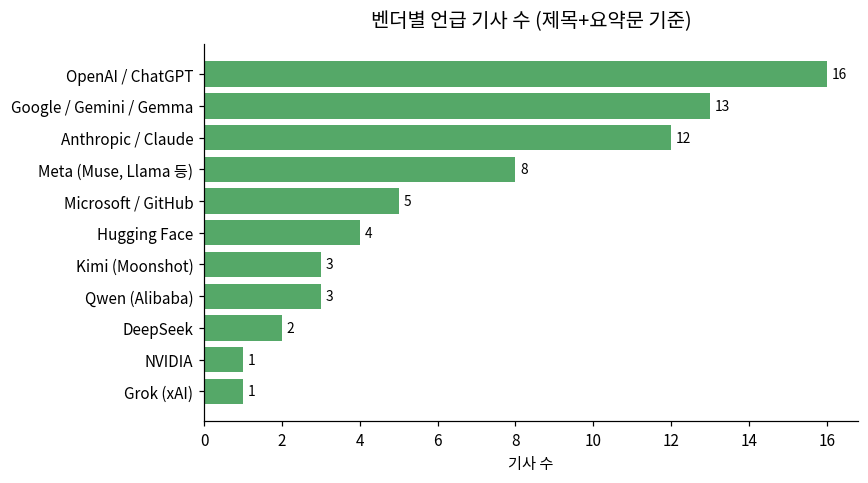

In [13]:
plot_data = vendor_counts.sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(plot_data.index, plot_data.values, color="#55A868")
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_title("벤더별 언급 기사 수 (제목+요약문 기준)", fontsize=13, pad=12)
ax.set_xlabel("기사 수")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

OpenAI, Google, Anthropic의 3강 구도이며, Qwen, DeepSeek, Kimi 같은 오픈 모델은 주로 로컬 실행 맥락에서 등장합니다. 제목에 "Here's What I Found", "Honest Review", "What It Actually Does" 같은 표현이 많은 것을 보면, 발표 내용 소개보다 직접 써본 비교 후기 형식이 주류입니다.

### 4.5 AI 시대의 직무 재편

커리어 관련 수치는 앞서 말했듯 과대 집계됐을 가능성이 있지만, 개별 제목은 분명한 신호를 보여줍니다. Forward Deployed Engineer를 다룬 글이 2편("Forward Deployed Engineer: AI's Hottest New Career, or Consulting With a Better Title?", "7 Steps to Become a Forward Deployed Engineer in 2026")이고, "The Roadmap to Becoming an AI Product Manager in 2026", "ML Engineer, AI Engineer, or LLM Engineer: Which Role Actually Builds What in 2026?", "What Companies Actually Mean When They Say They Want 'AI Experience'", "Data Scientists Are Becoming AI Managers, Not Model Builders" 같은 글도 있습니다. 모델을 직접 만드는 역할보다 AI를 업무와 제품에 연결하는 역할이 주목받는 흐름으로 읽힙니다.

In [14]:
career_pattern = r"engineer|career|role|product manager|ai experience|data scientists are"
df.loc[df["title"].str.lower().str.contains(career_pattern), ["published", "title"]].reset_index(drop=True)

,published,title
0,2026-10-26 14:00:00,The Roadmap to Becoming a Computer Vision Engineer in 2026
1,2026-10-23 14:00:00,What Companies Actually Mean When They Say They Want “AI Experience”
2,2026-10-20 14:00:00,The Roadmap to Becoming an AI Product Manager in 2026
3,2026-10-14 12:00:00,5 Fun Projects for LLM Inference Engineering
4,2026-10-07 14:00:00,"ML Engineer, AI Engineer, or LLM Engineer: Which Role Actually Builds What in 2026?"
5,2026-10-02 14:00:17,Python Foundations for Engineering: A KDnuggets Cheat Sheet
6,2026-10-02 14:00:04,"Forward Deployed Engineer: AI’s Hottest New Career, or Consulting With a Better Title?"
7,2026-09-29 12:00:36,5 Free Courses to Learn AI Engineering
8,2026-09-10 16:14:33,Feature Engineering in Scikit-Learn: A KDnuggets Cheat Sheet
9,2026-09-10 14:00:10,7 Steps to Become a Forward Deployed Engineer in 2026


### 4.6 데이터 도구 기본기는 여전히 중요

Python·데이터 도구 글은 43건(21.5%)으로, 10월에는 26.5%까지 올라갔습니다. "High-Performance Data Processing with Polars: A KDnuggets Cheat Sheet", "3 Polars Tricks for High-Performance Data Manipulation", "This Python Library Can Run Pandas Workloads Up to 20x Faster", "I Replaced Pip, Virtualenv, and Poetry With uv", "How to Use Marimo for Interactive Data Analysis", "3 Numba Tricks for Python Runtime Optimization" 등이 대표적입니다. "SQL vs Pandas vs AI Agents: Which Solves Analytics Problems Best?", "Turn Any CSV into an Executive Report with Python and AI"처럼 기존 데이터 분석 작업에 AI를 결합하는 글도 늘고 있습니다.

In [15]:
show_titles("Python·데이터 도구", n=12)

,published,title
0,2026-10-28 14:00:00,Access Multiple AI Models in Your Python Apps Using OpenRouter
1,2026-10-26 14:00:00,Building Your First AI Agent in Python with the OpenAI Agents SDK
2,2026-10-26 12:00:00,7 Advanced Python Design Patterns for Data Scientists
3,2026-10-22 14:00:00,How to Process Large JSON Files in Python With ijson
4,2026-10-20 12:00:00,5 Docker Containers for Devs
5,2026-10-19 16:00:00,"Claude Haiku 5.5: What’s New and How to Use It for Fast, Cheap AI Workflows"
6,2026-10-13 12:00:00,5 AutoHotkey Scripts for Data Scientists
7,2026-10-09 14:00:00,Build Your First MCP Server in Python (Stateless Spec Edition)
8,2026-10-08 14:00:00,Building AI Agents with Docker Agent
9,2026-10-06 12:00:00,5 Best Practices for Building Robust Python AI Libraries


### 4.7 약한 신호

비중은 작지만 눈여겨볼 주제도 있습니다. 거버넌스·사회(4%)에서는 "Could Your AI Systems Already Be High-Risk Under the EU AI Act?", "Who Pays for AI Data Centers?", "Understanding the Impact of AI on Job Markets"가 나왔고, 음성·멀티모달(5.5%)에서는 음성 전사 모델 비교, 음성 제어 에이전트, 로컬 영상 요약 파이프라인이 다뤄졌습니다.

In [16]:
pd.concat({
    "거버넌스·사회": show_titles("거버넌스·사회", n=8),
    "음성·멀티모달": show_titles("음성·멀티모달", n=11),
})

published  \
거버넌스·사회 0  2026-10-08 16:00:00   
        1  2026-10-06 14:00:20   
        2  2026-09-10 17:00:30   
        3  2026-09-08 16:00:12   
        4  2026-09-02 12:00:39   
        5  2026-08-26 14:00:53   
        6  2026-08-25 17:00:34   
        7  2026-07-19 09:50:14   
음성·멀티모달 0  2026-10-27 12:00:00   
        1  2026-10-26 14:00:00   
        2  2026-10-12 12:00:00   
        3  2026-09-29 14:00:00   
        4  2026-09-28 14:00:06   
        5  2026-09-01 14:00:47   
        6  2026-07-31 14:00:06   
        7  2026-07-30 14:06:48   
        8  2026-07-23 14:00:47   
        9  2026-07-10 12:00:51   
        10 2026-07-07 14:00:04   

                                                                                             title  
거버넌스·사회 0                    Bridging Algorithmic Design and Regulatory Standards in Enterprise AI  
        1                                                            Who Pays for AI Data Centers?  
        2    A Candid Abacus AI Review: The All-in-One AI Platform for Professionals & Enterprises  
        3   From RAG to Agentic AI: Building the Next Generation of Intelligent Enterprise Systems  
        4                         5 Real-World Applications of Agentic AI in Enterprise Automation  
        5                                            Understanding the Impact of AI on Job Markets  
        6      The Data & AI Leadership Questions That Will Define the Next Stage of Enterprise AI  
        7                          Could Your AI Systems Already Be High-Risk Under the EU AI Act?  
음성·멀티모달 0            Google Gemini Omni: What It Actually Does, What It Costs, and How It Compares  
        1                               The Roadmap to Becoming a Computer Vision Engineer in 2026  
        2                                             10 Hugging Face Models Worth Knowing in 2026  
        3              SuperWhisper s1-mini: The 600M Parameter Model Built Just for Transcription  
        4                                         Gemini 3.5 Transcribe vs OpenAI’s GPT-Transcribe  
        5                                                           Free Transcription with Speakr  
        6                                                      Building Voice-Controlled AI Agents  
        7                                         A Beginner’s Guide to Working with Claude Design  
        8                                                    Getting Started with OmniVoice-Studio  
        9                 Local Video Summarization Pipeline: Processing Frames with SmolVLM2-2.2B  
        10                  Zero-Shot Local Document Parsing with Gemma 4: Treating PDFs as Images

## 5. 월별 변화

In [17]:
MONTHLY_THEMES = ["AI 에이전트", "로컬·소형 모델", "추론·비용 최적화", "모델 출시·리뷰",
                  "Python·데이터 도구", "커리어·학습", "AI 코딩·바이브 코딩",
                  "평가·신뢰성", "파인튜닝·학습"]

monthly_share = df.groupby("month")[MONTHLY_THEMES].mean().mul(100).round(1).T
monthly_share.columns = ["7월*", "8월", "9월", "10월"]
print("월별 기사 수:", dict(zip(monthly_share.columns, df["month"].value_counts().sort_index().values)))
monthly_share

월별 기사 수: {'7월*': np.int64(55), '8월': np.int64(46), '9월': np.int64(50), '10월': np.int64(49)}


,7월*,8월,9월,10월
AI 에이전트,36.4,39.1,24.0,22.4
로컬·소형 모델,20.0,19.6,8.0,8.2
추론·비용 최적화,10.9,19.6,6.0,14.3
모델 출시·리뷰,20.0,21.7,24.0,22.4
Python·데이터 도구,21.8,15.2,22.0,26.5
커리어·학습,30.9,30.4,38.0,36.7
AI 코딩·바이브 코딩,12.7,10.9,4.0,10.2
평가·신뢰성,12.7,4.3,10.0,8.2
파인튜닝·학습,10.9,8.7,8.0,2.0


\* 7월에는 6월 말 기사 7건을 합쳐 집계했습니다(7월 기준 55건).

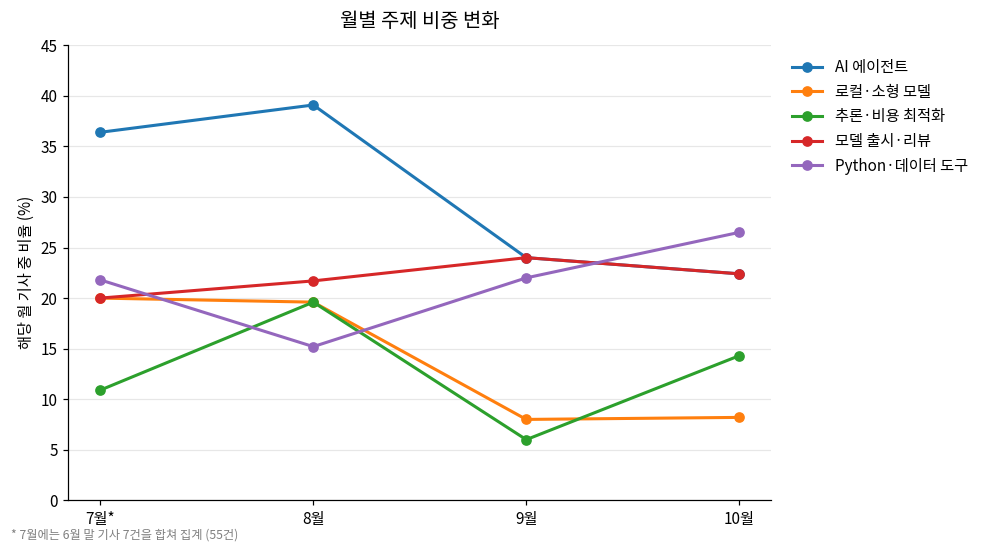

In [18]:
LINE_THEMES = ["AI 에이전트", "로컬·소형 모델", "추론·비용 최적화", "모델 출시·리뷰", "Python·데이터 도구"]
line_data = monthly_share.loc[LINE_THEMES].T

fig, ax = plt.subplots(figsize=(9, 5))
for theme in LINE_THEMES:
    ax.plot(line_data.index, line_data[theme], marker="o", linewidth=2, label=theme)
ax.set_title("월별 주제 비중 변화", fontsize=13, pad=12)
ax.set_ylabel("해당 월 기사 중 비율 (%)")
ax.set_ylim(0, 45)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "* 7월에는 6월 말 기사 7건을 합쳐 집계 (55건)", fontsize=8, color="gray")
plt.tight_layout()
plt.show()

7~8월에는 에이전트와 로컬 모델 비중이 높았고, 9~10월에는 둘 다 줄어든 대신 Python·데이터 도구와 커리어 글이 늘었습니다. 다만 월별 기사가 50건 안팎이라 1%p는 기사 0.5건 정도에 불과합니다. 따라서 에이전트(월 약 20건에서 11건으로)와 로컬 모델(약 10건에서 4건으로)의 감소 정도만 의미 있는 변화로 보고, 나머지 출렁임은 노이즈로 보는 것이 안전합니다.

In [19]:
# 비율이 아닌 실제 기사 수로 확인
df.groupby("month")[["AI 에이전트", "로컬·소형 모델"]].sum()

,AI 에이전트,로컬·소형 모델
month,,
2026-07,20,11
2026-08,18,9
2026-09,12,4
2026-10,11,4


에이전트 글이 줄었다고 해서 관심이 식었다고 단정하기는 어렵습니다. 후반부 제목들을 보면 입문형 "만들어보기" 글이 줄고 평가, 하네스("Google Open-Sources Harness²", "What I've Learned About DeepSeek Harness"), 오케스트레이션 같은 심화 주제로 옮겨가는 흐름이 보이기 때문입니다.

## 6. 분석의 한계

In [20]:
author_counts = df["author"].value_counts()
top3 = author_counts.head(3)
print(f"상위 3명 저자 기사 수: {top3.sum()}건 ({top3.sum() / len(df):.0%})")
author_counts.rename("기사 수").to_frame().head(10)

상위 3명 저자 기사 수: 112건 (56%)


,기사 수
author,
Shittu Olumide,41
Abid Ali Awan,38
Vinod Chugani,33
Kanwal Mehreen,21
KDnuggets,17
Nahla Davies,10
Nate Rosidi,10
Matthew Mayo,10
Iván Palomares Carrascosa,8


KDnuggets는 실무 튜토리얼 중심 매체이고, 상위 3명의 저자(Shittu Olumide 41건, Abid Ali Awan 38건, Vinod Chugani 33건)가 전체의 56%인 112건을 작성했습니다. 그래서 이 결과는 업계 전체보다는 "이 매체 편집진이 독자에게 중요하다고 본 것"에 가까워요. 키워드 규칙도 거칠어서 일부 분류는 과대·과소 집계됐을 수 있어요. 트렌드를 더 확실히 보려면 다른 소스(예: Towards Data Science, Hugging Face 블로그)를 같은 방식으로 수집해 교차 확인하는 방법이 있어요.

이 밖에도 분석 기간이 4개월로 짧아서 계절성이나 장기 추세를 판단하기 어렵습니다. 또한 기사 수는 조회수나 반응을 반영하지 않으므로, 실제 독자 관심도와 차이가 있을 수 있습니다.

## 부록: 주제 분류 키워드 규칙

제목과 요약문을 소문자로 바꾼 뒤 아래 정규표현식 중 하나라도 일치하면 해당 주제로 분류했습니다.

| 주제 | 정규표현식 |
|---|---|
| AI 에이전트 | `\bagent\|agentic\|autonomous\|multi-agent` |
| AI 코딩·바이브 코딩 | `coding agent\|coding assistant\|claude code\|vibe coding\|ai-generated code\|coding model\|ai coding\|codex\|gemini cli\|pi coding` |
| 로컬·소형 모델 | `\blocal\b\|locally\|small language\|\bslm\|ollama\|llama\.cpp\|\bmlx\b\|on-device\|smol` |
| MCP | `\bmcp\b\|model context protocol` |
| RAG·검색 | `\brag\b\|retrieval` |
| 추론·비용 최적화 | `inference\|latency\|quantiz\|token\|kv cache\|speculative\|prun\|cost\|cheap` |
| 프롬프트·명세 엔지니어링 | `prompt\|specification engineering\|constrain\|structured (output\|generation)\|outlines` |
| 파인튜닝·학습 | `fine-tun\|training\|pretrain` |
| 모델 출시·리뷰 | `gemini\|claude\|chatgpt\|openai\|deepseek\|qwen\|grok\|kimi\|muse\|gemma\|minimax\|mythos\|review` |
| 평가·신뢰성 | `\beval\|benchmark\|hallucinat\|trust\|check` |
| 커리어·학습 | `roadmap\|career\|course\|interview\|resources\|\brole\|job\|engineer in 2026\|learn` |
| Python·데이터 도구 | `pandas\|polars\|\bpython\b\|numba\|\buv\b\|marimo\|csv\|json\|sql\|docker` |
| 고전 ML·통계 | `statistic\|probability\|time series\|scikit-learn\|algorithm\|feature engineering\|central limit` |
| 거버넌스·사회 | `eu ai act\|regulat\|data center\|job market\|leadership\|enterprise` |
| 음성·멀티모달 | `voice\|transcri\|video\|vision\|image\|speech\|whisper` |